# **Лабораторна робота №5.** Часові ряди: моделі AR, MA, ARMA, ARIMA

### Крічфалуши Дар'я, 2к. Маг., група МатШІ

**Мета роботи:** опанувати базові поняття аналізу часових рядів; навчитися перевіряти стаціонарність ряду та виконувати його диференціювання; будувати й інтерпретувати моделі авторегресії AR, ковзного середнього MA, ARMA та ARIMA; виконувати ідентифікацію порядків p , d , q за допомогою ACF та PACF; реалізувати аналіз і прогнозування часових рядів у Python; оцінювати якість моделей за залишками та інформаційними критеріями.

## Завдання (Варіант 4)

1. Завантажте дані свого варіанта у вигляді CSV-файлу з колонками date та value.
2. Побудуйте графік вихідного часового ряду.
3. Побудуйте графіки ковзного середнього та ковзного стандартного відхилення.
4. Виконайте тест Дікі–Фуллера для вихідного ряду та для ряду перших різниць.
5. Побудуйте ACF і PACF для стаціонарного ряду.
d
6. Побудуйте моделі AR(1), MA(1), ARMA(1, 1), ARIMA(p, d, q), обрані за
результатами аналізу.
7. Порівняйте моделі за AIC, BIC, RMSE та MAE.
8. Побудуйте прогноз на 12 кроків уперед із довірчими інтервалами.
9. Проаналізуйте залишки найкращої моделі: графік, ACF залишків, гістограма, тест Льюнга–Бокса.

### Варіант 4: ARMA(1, 1)-процес

**Формула генерації даних**

Реальні дані недоступні, тому ряд згенеровано відповідно до варіанта:

$$y_t = 10 + 0.5\,y_{t-1} + \varepsilon_t + 0.4\,\varepsilon_{t-1}, \qquad \varepsilon_t \sim N(0,\,4)$$

Кількість спостережень: $T = 180$. Параметри процесу: $c = 10$, $\phi_1 = 0.5$, $\theta_1 = 0.4$, $\sigma^2_\varepsilon = 4$ (отже $\sigma_\varepsilon = 2$).

**Додаткове завдання варіанта:** записати рівняння моделі через оператор зсуву $B$.

Оскільки процес відомий, можна наперед обчислити величини, з якими звірятимемо вибіркові оцінки:

1. Математичне сподівання
$$\mu = \frac{c}{1-\phi_1} = \frac{10}{1-0.5} = 20$$

2. Автоковаріація
$$\gamma(0) = \sigma^2_\varepsilon\,\frac{1 + 2\phi_1\theta_1 + \theta_1^2}{1-\phi_1^2} = 4\cdot\frac{1 + 0.4 + 0.16}{0.75} = \frac{6.24}{0.75} = 8.32$$

3. Автокореляційна функція (ACF)
$$\rho(1) = \frac{(1+\phi_1\theta_1)(\phi_1+\theta_1)}{1 + 2\phi_1\theta_1 + \theta_1^2} = \frac{1.2 \cdot 0.9}{1.56} = 0.6923, \quad \rho(k) = \phi_1\,\rho(k-1)\ \ (k \ge 2)$$


$⟹\rho(2) = 0.3462$, $\rho(3) = 0.1731$.



---



## **Частина 1.** Ручні розрахунки

У якості додатка додано `"L5p1_Krichfalushy.pdf"` файл із ручними розрахунками та виконаними завданнями частини 1.


## **Частина 2.** Моделювання Python

### 2.0. Імпортуємо бібліотеки

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from statsmodels.tools.sm_exceptions import ConvergenceWarning, EstimationWarning
warnings.simplefilter("ignore")

for _c in (ConvergenceWarning, EstimationWarning, UserWarning, FutureWarning, RuntimeWarning):
    warnings.filterwarnings("ignore", category=_c)

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from sklearn.metrics import mean_squared_error, mean_absolute_error

plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.3, "figure.facecolor": "white"})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")


### 2.1. Генерація даних у CSV

Ряд генерується за формулою варіанта 4 і зберігається у файл data.csv з колонками `date` і `value`.

Початкове значення взято рівним теоретичному середньому $y_0=\mu=20$, щоб уникнути перехідного процесу на початку ряду.

In [2]:
T = 180   # к-ть спостережень

C = 10.0; PHI = 0.5; THETA = 0.4
SIGMA = 2.0
SEED = 0

rng = np.random.default_rng(SEED)
eps = rng.normal(0.0, SIGMA, T+1)

y = np.empty(T + 1)
y[0] = C / (1 - PHI)

for t in range(1, T+1):
  y[t] = C + PHI * y[t-1] + eps[t] + THETA * eps[t-1]

y = y[1:]

dates = pd.date_range("2010-01-01", periods=T, freq="MS")
pd.DataFrame({"date": dates, "value": y}).to_csv("data.csv", index=False)


In [3]:
# Завантаження даних
df = pd.read_csv("data.csv", parse_dates=["date"])
df = df.set_index("date").asfreq("MS")
y = df["value"]

print(f"Завантажено: {len(y)} спостережень за {y.index[0].date()} ... {y.index[-1].date()}\n")
print(y.head().to_string())

print(f"\nВибіркове середнє = {y.mean():.4f}   (Теоретичне μ = {C/(1-PHI)})")
print(f"Вибіркова дисперсія = {y.var(ddof=1):.4f}   (Теоретична γ(0) = 8.32)")


Завантажено: 180 спостережень за 2010-01-01 ... 2024-12-01

date
2010-01-01   19.8364
2010-02-01   21.0933
2010-03-01   21.2688
2010-04-01   19.6470
2010-05-01   20.1181
Freq: MS

Вибіркове середнє = 20.1810   (Теоретичне μ = 20.0)
Вибіркова дисперсія = 9.0060   (Теоретична γ(0) = 8.32)


### 2.2. Графік вихідного часового ряду

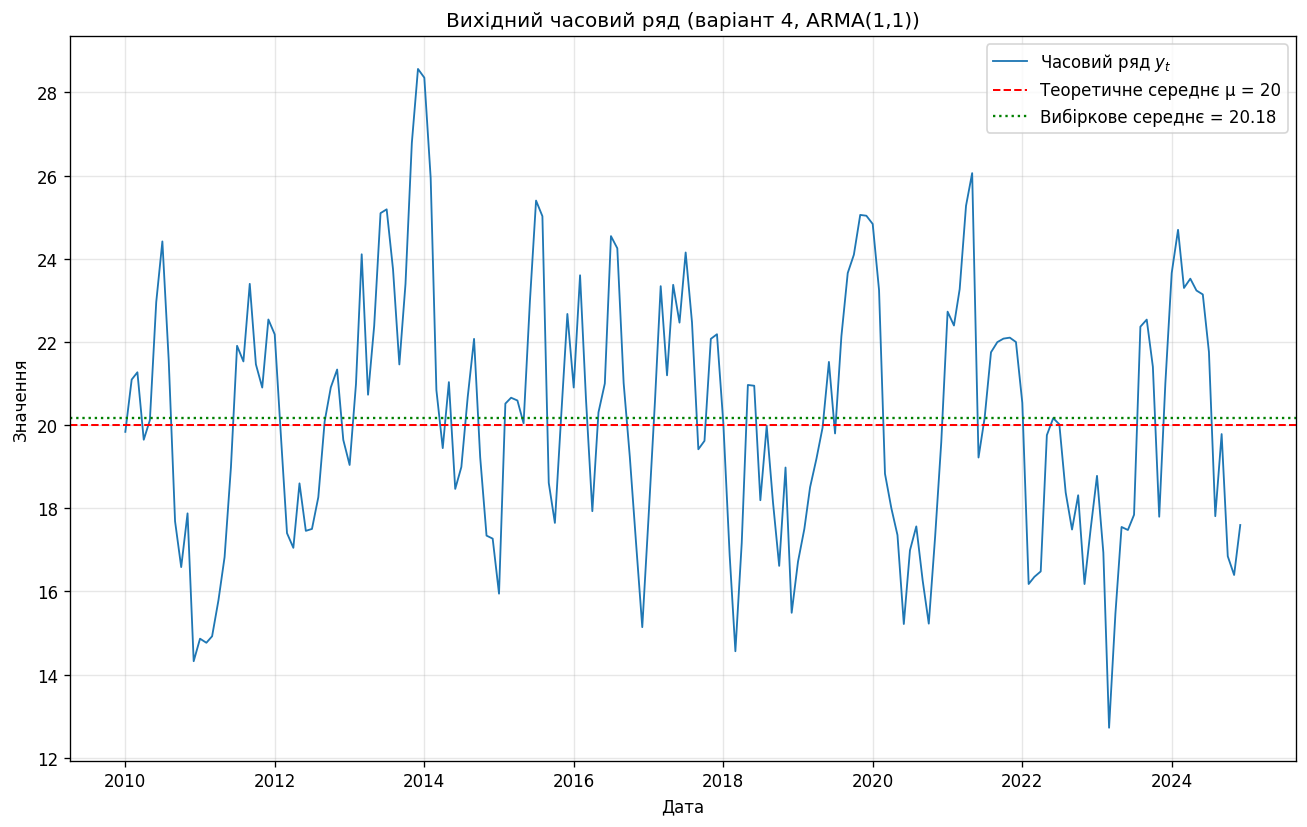

Візуальний аналіз: тренду немає, ряд коливається навколо сталого рівня ≈ 20;
сезонності не видно; амплітуда коливань візуально стабільна у часі.


In [4]:
plt.figure(figsize=(11, 7))
plt.plot(y, lw=1.1, label="Часовий ряд $y_t$")
plt.axhline(C / (1 - PHI), c="red", ls="--", lw=1.2,
            label=f"Теоретичне середнє μ = {C/(1-PHI):.0f}")
plt.axhline(y.mean(), c="green", ls=":", lw=1.4,
            label=f"Вибіркове середнє = {y.mean():.2f}")
plt.title("Вихідний часовий ряд (варіант 4, ARMA(1,1))")
plt.xlabel("Дата"); plt.ylabel("Значення")
plt.legend(); plt.tight_layout(); plt.show()

print("Візуальний аналіз: тренду немає, ряд коливається навколо сталого рівня ≈ 20;")
print("сезонності не видно; амплітуда коливань візуально стабільна у часі.")


### 2.3. Ковзне середнє та ковзне стандартне відхилення

Якщо **ряд стаціонарний**, ковзне середнє має коливатися навколо горизонтальної лінії без систематичного дрейфу, а ковзне стандартне відхилення - залишатися приблизно сталим.

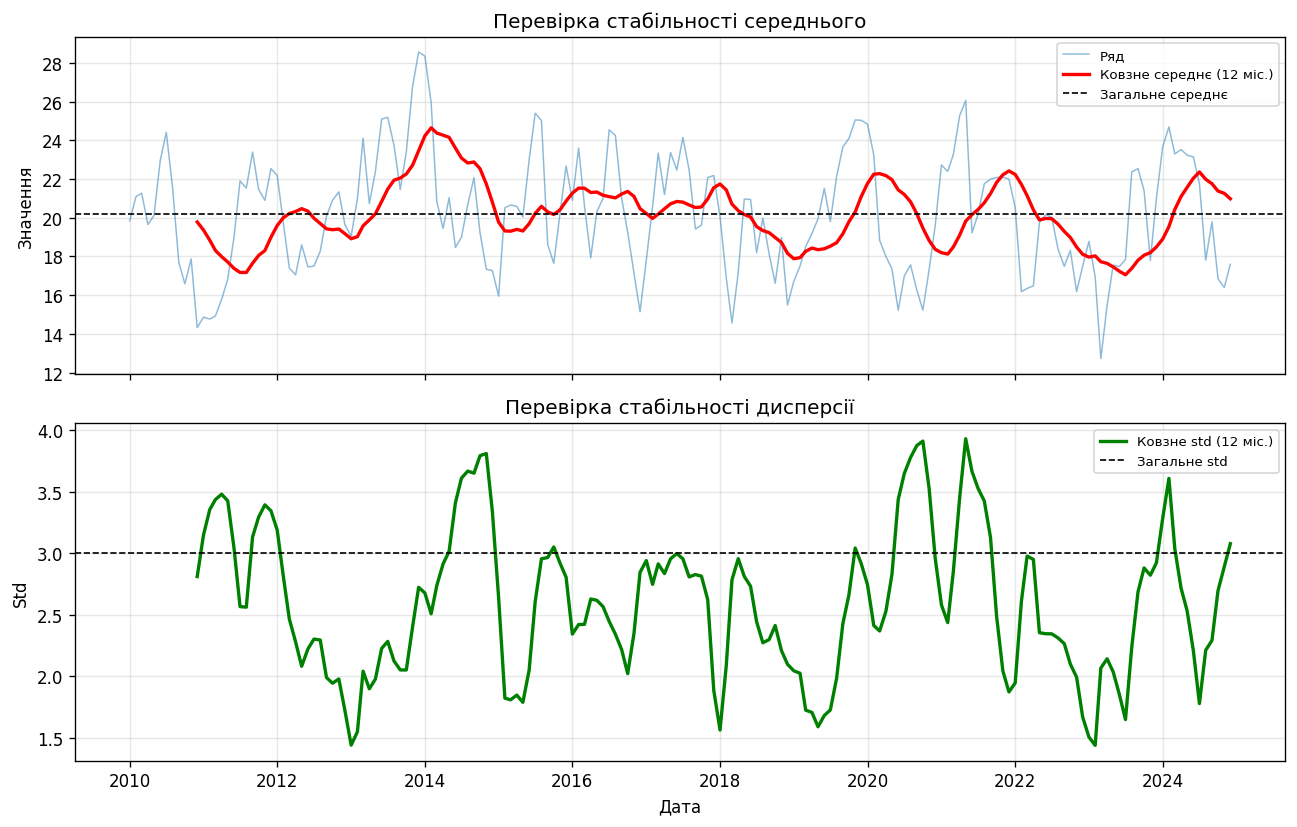

ковзне середнє: від 17.052 до 24.646  (розмах 7.594)
ковзне std: від 1.436 до 3.931  (розмах 2.495)

Висновок: обидві характеристики коливаються навколо сталих рівнів без
систематичного зростання чи спадання — ознака стаціонарності.


In [5]:
W = 12
rolling_mean = y.rolling(window=W).mean()
rolling_std = y.rolling(window=W).std()

fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

ax[0].plot(y, lw=0.9, alpha=0.5, label="Ряд")
ax[0].plot(rolling_mean, lw=2, c="red", label=f"Ковзне середнє ({W} міс.)")
ax[0].axhline(y.mean(), c="black", ls="--", lw=1, label="Загальне середнє")
ax[0].set_ylabel("Значення")
ax[0].set_title("Перевірка стабільності середнього")
ax[0].legend(fontsize=8)

ax[1].plot(rolling_std, lw=2, c="green", label=f"Ковзне std ({W} міс.)")
ax[1].axhline(y.std(ddof=1), c="black", ls="--", lw=1, label="Загальне std")
ax[1].set_xlabel("Дата"); ax[1].set_ylabel("Std")
ax[1].set_title("Перевірка стабільності дисперсії")
ax[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

print(f"ковзне середнє: від {rolling_mean.min():.3f} до {rolling_mean.max():.3f}"
      f"  (розмах {rolling_mean.max()-rolling_mean.min():.3f})")
print(f"ковзне std: від {rolling_std.min():.3f} до {rolling_std.max():.3f}"
      f"  (розмах {rolling_std.max()-rolling_std.min():.3f})")
print("\nВисновок: обидві характеристики коливаються навколо сталих рівнів без")
print("систематичного зростання чи спадання — ознака стаціонарності.")


### 2.4. Тест Дікі-Фуллера

Це статистичний тест, який використовується в економетриці та аналізі часових рядів для перевірки наявності одиничного кореня (unit root), що вказує на *нестаціонарність ряду*.

**Нульова гіпотеза $H_0$:** ряд має одиничний корінь, тобто є нестаціонарним.

**Альтернатива $H_1$:** ряд стаціонарний.

Якщо $p$-value $<0.05$, то $H_0$ відхиляється на рівні значущості $5%$ - ряд можна вважати стаціонарним.

In [6]:
def dickey_fuller_test(series):
  result = adfuller(series.dropna())
  print(f"ADF statistic: {result[0]:.4f}")
  print(f"p-value: {result[1]:.6f}")
  print(f"використано лагів: {result[2]},  спостережень: {result[3]}\n")

  for k, v in result[4].items():
    print(f"critical value {k}: {v:.4f}")
  if result[1] < 0.05:
    print("Висновок: ряд можна вважати стаціонарним на рівні 5%")
  else:
    print("Висновок: немає підстав вважати ряд стаціонарним")
  return result

# тест на вихідному ряді
res_level = dickey_fuller_test(y)

# тест на перших різницях
y_diff = y.diff().dropna()
res_diff = dickey_fuller_test(y_diff)

print(f"Для вихідного ряду ADF = {res_level[0]:.4f} значно менша за критичне значення")
print(f"{res_level[4]["5%"]:.4f} на рівні 5%, p-value ≈ {res_level[1]:.2e} < 0.05.")
print("Отже H_0 про одиничний корінь відхиляється: ряд СТАЦІОНАРНИЙ вже на рівнях,")
print("диференціювання не потрібне => d = 0.")
print(f"\nДисперсія: Var(y) = {y.var(ddof=1):.4f},  Var(Δy) = {y_diff.var(ddof=1):.4f}")


ADF statistic: -5.9314
p-value: 0.000000
використано лагів: 1,  спостережень: 178

critical value 1%: -3.4676
critical value 5%: -2.8779
critical value 10%: -2.5755
Висновок: ряд можна вважати стаціонарним на рівні 5%
ADF statistic: -9.7396
p-value: 0.000000
використано лагів: 2,  спостережень: 176

critical value 1%: -3.4681
critical value 5%: -2.8781
critical value 10%: -2.5756
Висновок: ряд можна вважати стаціонарним на рівні 5%
Для вихідного ряду ADF = -5.9314 значно менша за критичне значення
-2.8779 на рівні 5%, p-value ≈ 2.38e-07 < 0.05.
Отже H_0 про одиничний корінь відхиляється: ряд СТАЦІОНАРНИЙ вже на рівнях,
диференціювання не потрібне => d = 0.

Дисперсія: Var(y) = 9.0060,  Var(Δy) = 4.5142


### 2.5. ACF і PACF стаціонарного ряду

Оскільки тест Дікі–Фуллера показав стаціонарність **вихідного ряду**, ACF і PACF будуємо саме для нього (а не для різниць). Для повноти наводимо також ACF/PACF перших різниць, щоб продемонструвати наслідки надлишкового диференціювання.

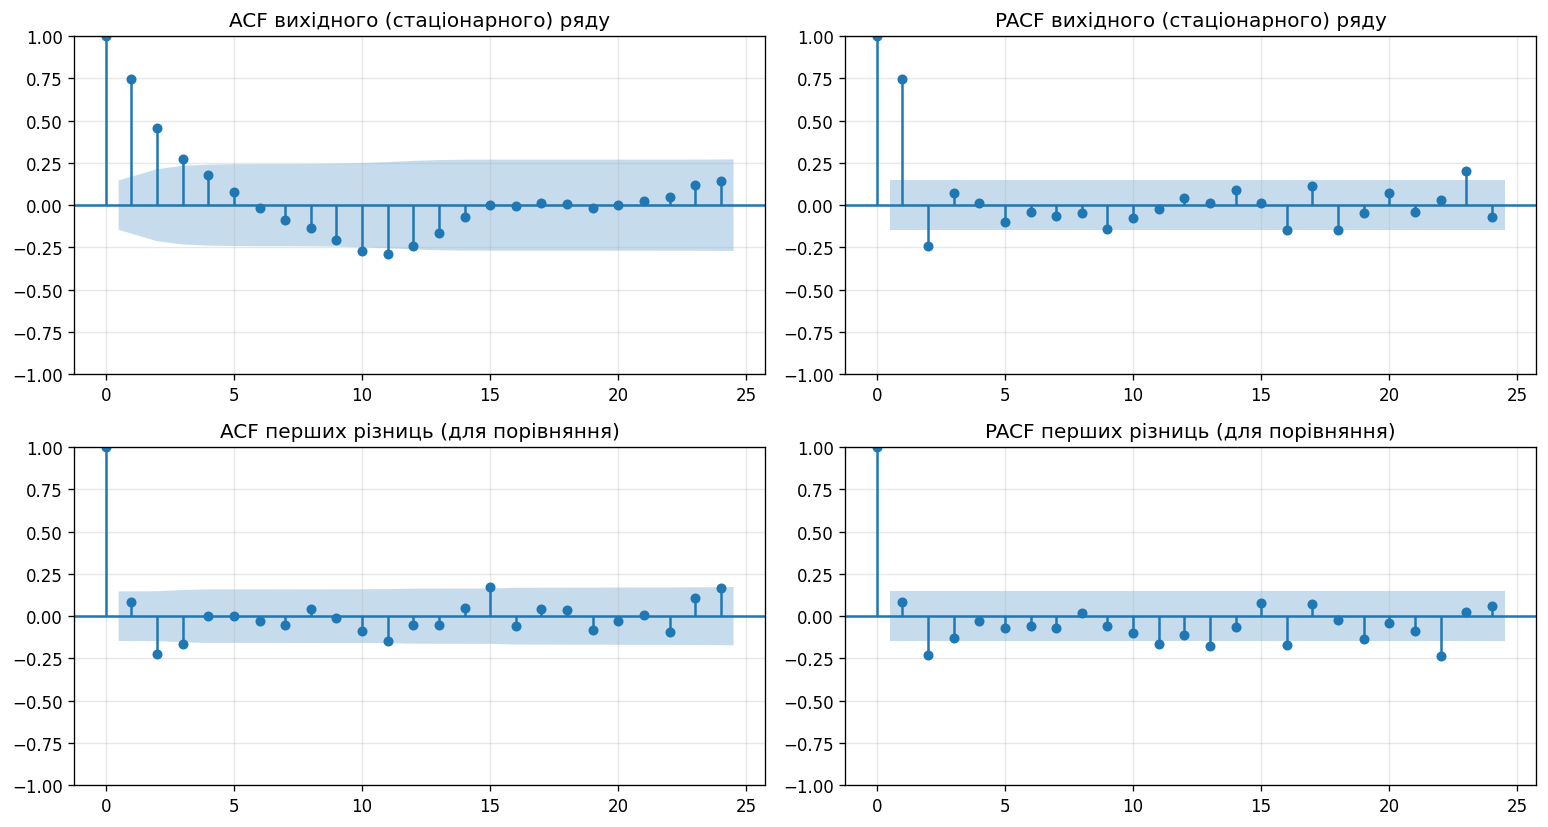

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))

plot_acf(y, ax=axes[0, 0], lags=24)
axes[0, 0].set_title("ACF вихідного (стаціонарного) ряду")
plot_pacf(y, ax=axes[0, 1], lags=24, method="ywm")
axes[0, 1].set_title("PACF вихідного (стаціонарного) ряду")

plot_acf(y_diff, ax=axes[1, 0], lags=24)
axes[1, 0].set_title("ACF перших різниць (для порівняння)")
plot_pacf(y_diff, ax=axes[1, 1], lags=24, method="ywm")
axes[1, 1].set_title("PACF перших різниць (для порівняння)")

plt.tight_layout()
plt.show()


Числові значення ACF/PACF

In [8]:
from statsmodels.tsa.stattools import acf, pacf


acf_vals = acf(y, nlags=8)
pacf_vals = pacf(y, nlags=8, method="ywm")
ci = 1.96/np.sqrt(len(y))   # межі значущості

r1_th = (1 + PHI*THETA) * (PHI + THETA) / (1 + 2*PHI*THETA + THETA**2)
theor = [1.0] + [r1_th * PHI**(k-1) for k in range(1, 9)]

print(f"межі значущості: +- {ci:.4f}\n")
print(f"{'лаг':>4}{'ACF':>10}{'ACF теор':>11}{'PACF':>10}{'значущі':>12}")
print("-" * 47)

for k in range(1, 9):
  sig = ("ACF" if abs(acf_vals[k]) > ci else "  ") + \
        (" PACF" if abs(pacf_vals[k]) > ci else "")
  print(f"{k:>4}{acf_vals[k]:>10.4f}{theor[k]:>11.4f}{pacf_vals[k]:>10.4f}{sig:>12}")

print("Ідентифікація порядків:")
print("ACF : затухає поступово (не обривається після лагу 1) => це не MA(1)")
print("PACF: також затухає, зі зміною знака => це не чистий AR(p)")
print("Обидві функції затухають поступово => модель ЗМІШАНА: ARMA(p,q)")


межі значущості: +- 0.1461

 лаг       ACF   ACF теор      PACF     значущі
-----------------------------------------------
   1    0.7487     0.6923    0.7487    ACF PACF
   2    0.4546     0.3462   -0.2408    ACF PACF
   3    0.2721     0.1731    0.0725         ACF
   4    0.1760     0.0865    0.0106         ACF
   5    0.0778     0.0433   -0.1021            
   6   -0.0139     0.0216   -0.0387            
   7   -0.0881     0.0108   -0.0619            
   8   -0.1379     0.0054   -0.0472            
Ідентифікація порядків:
ACF : затухає поступово (не обривається після лагу 1) => це не MA(1)
PACF: також затухає, зі зміною знака => це не чистий AR(p)
Обидві функції затухають поступово => модель ЗМІШАНА: ARMA(p,q)


### 2.6. Побудова моделей AR, MA, ARMA, ARIMA

Будуємо чотири моделі:
1. **AR($1$)** = ARIMA(1,0,0)
2. **MA($1$)** = ARIMA(0,0,1)
3. **ARMA($1,1$)** = ARIMA(1,0,1)
4. **ARIMA($p,d,q$)**, обрана за результатами аналізу

Для вибору останньої виконуємо сітковий пошук за критерієм AIC.

Сітковий пошук ARIMA(p,d,q)

In [9]:
grid = []

with warnings.catch_warnings():
  warnings.simplefilter("ignore")
  for p in range(4):
    for d in range(2):
      for q in range(4):
        if p == 0 and q == 0:
          continue
        try:
          f = ARIMA(y, order=(p, d, q), trend="c" if d == 0 else "t").fit()
          grid.append({"order": (p, d, q), "AIC": f.aic, "BIC": f.bic})
        except Exception:
          pass

grid_df = pd.DataFrame(grid).sort_values("AIC").reset_index(drop=True)
print("Tоп-8 за AIC:")
print(grid_df.head(8).to_string(index=False))

best_order = grid_df.loc[0, "order"]
print(f"\nНайкраща за AIC: ARIMA{best_order}")
print(f"Найкраща за BIC: ARIMA{grid_df.sort_values('BIC').iloc[0]['order']}")


Tоп-8 за AIC:
    order      AIC      BIC
(1, 0, 1) 754.3170 767.0889
(2, 0, 0) 754.8552 767.6270
(1, 1, 2) 755.6797 771.6167
(3, 0, 0) 755.9087 771.8735
(1, 0, 2) 755.9669 771.9317
(2, 0, 1) 756.1158 772.0806
(2, 1, 1) 756.3559 772.2928
(2, 0, 3) 757.1654 779.5161

Найкраща за AIC: ARIMA(1, 0, 1)
Найкраща за BIC: ARIMA(1, 0, 1)


In [11]:
# оцінювання моделей
models = {
    "AR(1)": (1, 0, 0),
    "MA(1)": (0, 0, 1),
    "ARMA(1, 1)": (1, 0, 1),
    "ARIMA(1, 1, 1)": (1, 1, 1)
}

if best_order not in models.values():
  models[f"ARIMA{best_order}"] = best_order

results = {}
with warnings.catch_warnings():
  warnings.simplefilter("ignore")
  for name, order in models.items():
    results[name] = ARIMA(y, order=order,
                          trend="c" if order[1] == 0 else "t").fit()
for name, fitted in results.items():
  order = models[name]
  print(f">> ARIMA{order}")
  print(fitted.summary())



>> ARIMA(1, 0, 0)
                               SARIMAX Results                                
Dep. Variable:                  value   No. Observations:                  180
Model:                 ARIMA(1, 0, 0)   Log Likelihood                -378.651
Date:                Sun, 15 Nov 2026   AIC                            763.303
Time:                        22:17:30   BIC                            772.881
Sample:                    01-01-2010   HQIC                           767.186
                         - 12-01-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         20.1343      0.610     33.020      0.000      18.939      21.329
ar.L1          0.7477      0.050     14.865      0.000       0.649       0.846
sigma2         3.9150      0.469  

Рівняння побудованих моделей з оціненими коефіцієнтами

In [18]:
for name, res in results.items():
  p_ = res.params
  if name == "AR(1)":
    print(f"AR(1): y_t = {p_['const']*(1-p_["ar.L1"]):.4f} + "
          f"{p_['ar.L1']:.4f}*y_(t-1) + ε_t")
    print(f"(у вигляді відхилень: y_t - {p_['const']:.4f} = "
          f"{p_['ar.L1']:.4f}*(y_(t-1) - {p_['const']:.4f}) + ε_t)\n")
  elif name == "MA(1)":
    print(f"MA(1): y_t = {p_['const']:.4f} + ε_t + {p_['ma.L1']:.4f}*ε_(t-1)\n")
  elif name == "ARMA(1, 1)":
    print(f"ARMA(1,1): y_t = {p_['const']*(1-p_['ar.L1']):.4f} + "
              f"{p_['ar.L1']:.4f}*y_(t-1) + ε_t + {p_['ma.L1']:.4f}*ε_(t-1)")
    print(f"(істинні значення: 10 + 0.5*y_(t-1) + ε_t + 0.4*ε_(t-1))\n")
  elif name == "ARIMA(1, 1, 1)":
    print(f"ARIMA(1,1,1): Δy_t = {p_['ar.L1']:.4f}*Δy_(t-1) + ε_t + "
          f"{p_['ma.L1']:.4f}*ε_(t-1)")

print("\nЗначущість коефіцієнтів ARMA(1,1) (|z| > 1.96 => значущий на рівні 5%)")
arma = results["ARMA(1, 1)"]

tbl = pd.DataFrame({"оцінка": arma.params, "ст. похибка": arma.bse,
                    "z": arma.params / arma.bse, "p-value": arma.pvalues})
print(tbl.to_string())




AR(1): y_t = 5.0796 + 0.7477*y_(t-1) + ε_t
(у вигляді відхилень: y_t - 20.1343 = 0.7477*(y_(t-1) - 20.1343) + ε_t)

MA(1): y_t = 20.1724 + ε_t + 0.6732*ε_(t-1)

ARMA(1,1): y_t = 7.6440 + 0.6207*y_(t-1) + ε_t + 0.3119*ε_(t-1)
(істинні значення: 10 + 0.5*y_(t-1) + ε_t + 0.4*ε_(t-1))

ARIMA(1,1,1): Δy_t = -0.3430*Δy_(t-1) + ε_t + 0.4782*ε_(t-1)

Значущість коефіцієнтів ARMA(1,1) (|z| > 1.96 => значущий на рівні 5%)
        оцінка  ст. похибка       z  p-value
const  20.1508       0.5129 39.2849   0.0000
ar.L1   0.6207       0.0759  8.1780   0.0000
ma.L1   0.3119       0.0950  3.2843   0.0010
sigma2  3.6806       0.4369  8.4242   0.0000


### 2.7. Порівняння моделей за AIC, BIC, RMSE, MAE

**Зауваження.** RMSE та MAE обчислюємо двома способами:
1. in-sample - за залишками моделі на всьому ряді (показує якість підгонки);
2. out-of-sample - на відкладеній тестовій вибірці з останніх 12 спостережень (показує реальну прогнозну здатність).

In [19]:
TEST_SIZE = 12

train, test = y.iloc[:-TEST_SIZE], y.iloc[-TEST_SIZE:]
print(f"навчальна вибірка: {len(train)} спостережень, "
      f"тестова: {len(test)} ({test.index[0].date()}...{test.index[-1].date()})\n)")

rows = []
for name, order in models.items():
  full = results[name]
  # in-sample
  fitted_vals = full.fittedvalues
  rmse_in = np.sqrt(mean_squared_error(y, fitted_vals))
  mae_in = mean_absolute_error(y, fitted_vals)
  # out-of-sample
  with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    m_tr = ARIMA(train, order=order, trend="c" if order[1] == 0 else "t").fit()
  fc = m_tr.forecast(TEST_SIZE)
  rmse_out = np.sqrt(mean_squared_error(test, fc))
  mae_out = mean_absolute_error(test, fc)
  rows.append({
      "Модель": name, "order": str(order), "AIC": full.aic, "BIC": full.bic,
      "RMSE_in": rmse_in, "MAE_in": mae_in,
      "RMSE_out": rmse_out, "MAE_out": mae_out
  })

comparison = pd.DataFrame(rows).set_index("Модель")
print("Порівняння моделей")
print(comparison.sort_values("AIC").to_string())

print("\nНайкраща за кожним критерієм")
for col in ["AIC", "BIC", "RMSE_in", "MAE_in", "RMSE_out", "MAE_out"]:
  print(f"{col:10s}: {comparison[col].idxmin()}  ({comparison[col].min():.4f})")

best_name = comparison["AIC"].idxmin()
best_model = results[best_name]
print(f"\nОбрана модель: {best_name}")


навчальна вибірка: 168 спостережень, тестова: 12 (2024-01-01...2024-12-01)
)
Порівняння моделей
                    order      AIC      BIC  RMSE_in  MAE_in  RMSE_out  MAE_out
Модель                                                                         
ARMA(1, 1)      (1, 0, 1) 754.3170 767.0889   1.9187  1.5451    2.7156   2.5630
AR(1)           (1, 0, 0) 763.3026 772.8814   1.9787  1.6074    2.8774   2.7211
ARIMA(1, 1, 1)  (1, 1, 1) 781.0816 793.8312   2.5615  1.7830    3.0389   2.6606
MA(1)           (0, 0, 1) 798.2815 807.8604   2.1822  1.7735    2.9248   2.7173

Найкраща за кожним критерієм
AIC       : ARMA(1, 1)  (754.3170)
BIC       : ARMA(1, 1)  (767.0889)
RMSE_in   : ARMA(1, 1)  (1.9187)
MAE_in    : ARMA(1, 1)  (1.5451)
RMSE_out  : ARMA(1, 1)  (2.7156)
MAE_out   : ARMA(1, 1)  (2.5630)

Обрана модель: ARMA(1, 1)


Стовпчикова діаграма порівняння

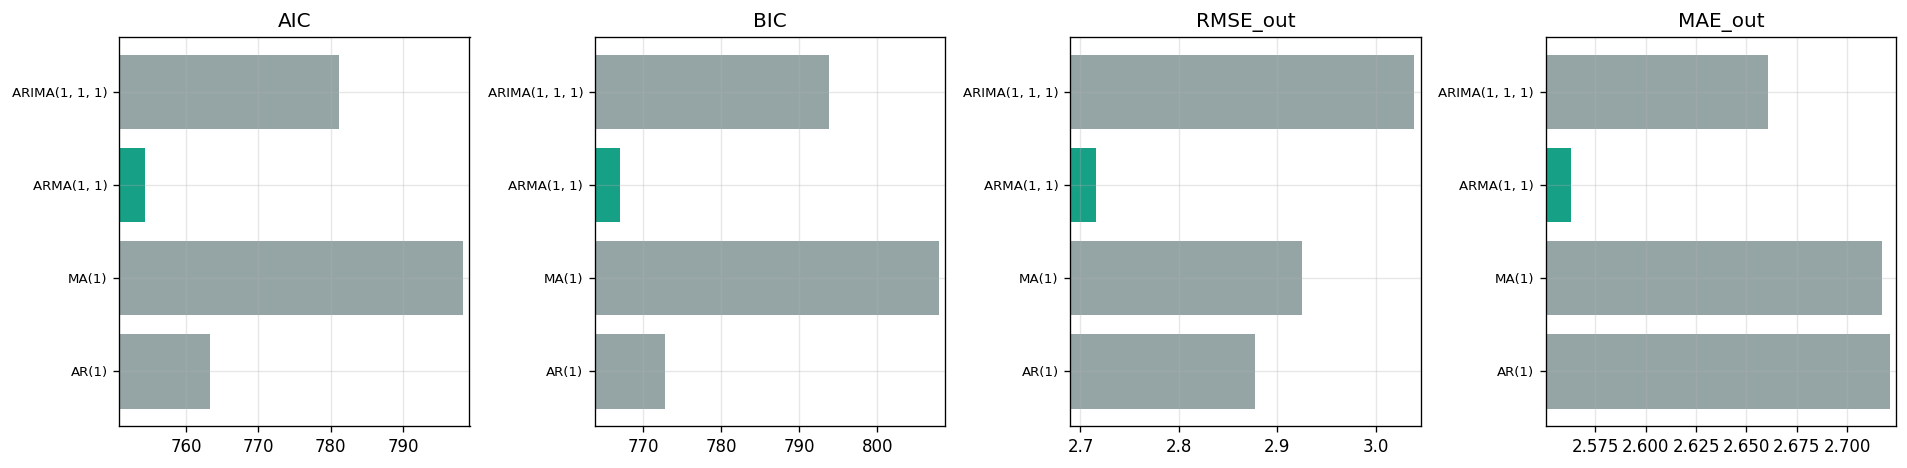

In [20]:
fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for i, col in enumerate(['AIC', 'BIC', 'RMSE_out', 'MAE_out']):
    vals = comparison[col]
    colors = ['#16a085' if v == vals.min() else '#95a5a6' for v in vals]
    ax[i].barh(range(len(vals)), vals, color=colors)
    ax[i].set_yticks(range(len(vals)))
    ax[i].set_yticklabels(vals.index, fontsize=8)
    ax[i].set_title(col)
    lo, hi = vals.min(), vals.max()
    ax[i].set_xlim(lo - 0.08 * (hi - lo + 1e-9), hi + 0.02 * (hi - lo + 1e-9))
plt.tight_layout(); plt.show()


### 2.8. Прогноз на 12 кроків уперед із довірчими інтервалами

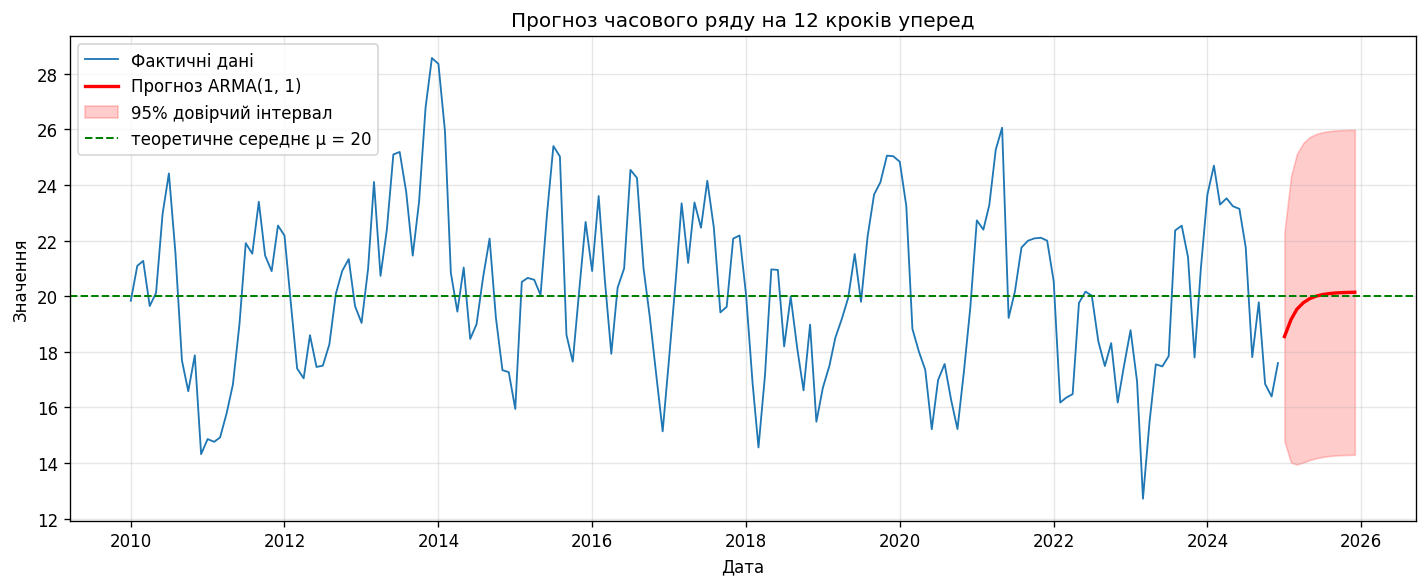

ПРОГНОЗНІ ЗНАЧЕННЯ
            прогноз  нижня межа 95%  верхня межа 95%  ширина ДІ
2025-01-01  18.5484         14.7883          22.3086     7.5204
2025-02-01  19.1563         14.0146          24.2979    10.2833
2025-03-01  19.5336         13.9502          25.1169    11.1667
2025-04-01  19.7677         14.0233          25.5122    11.4889
2025-05-01  19.9130         14.1077          25.7184    11.6107
2025-06-01  20.0032         14.1746          25.8319    11.6572
2025-07-01  20.0592         14.2217          25.8968    11.6751
2025-08-01  20.0940         14.2530          25.9350    11.6820
2025-09-01  20.1155         14.2732          25.9579    11.6846
2025-10-01  20.1289         14.2861          25.9718    11.6857
2025-11-01  20.1372         14.2942          25.9803    11.6860
2025-12-01  20.1424         14.2993          25.9855    11.6862

Прогноз швидко збігається до середнього рівня 20.1424
(теоретичне μ = 20.0). Це нормальна поведінка стаціонарної ARMA:
вплив останніх спостережень з

In [21]:
H = 12
forecast = best_model.get_forecast(steps=H)
mean_forecast = forecast.predicted_mean
conf_int = forecast.conf_int()

plt.figure(figsize=(12, 5))
plt.plot(y, label="Фактичні дані", lw=1.1)
plt.plot(mean_forecast, label=f"Прогноз {best_name}", color="red", lw=2)
plt.fill_between(conf_int.index, conf_int.iloc[:, 0], conf_int.iloc[:, 1],
                 color="red", alpha=0.2, label="95% довірчий інтервал")
plt.axhline(C / (1 - PHI), c='green', ls='--', lw=1.2,
            label=f"теоретичне середнє μ = {C/(1-PHI):.0f}")
plt.title(f"Прогноз часового ряду на {H} кроків уперед")
plt.xlabel("Дата"); plt.ylabel("Значення")
plt.legend(); plt.tight_layout(); plt.show()

fc_table = pd.DataFrame({
    "прогноз": mean_forecast,
    "нижня межа 95%": conf_int.iloc[:, 0],
    "верхня межа 95%": conf_int.iloc[:, 1],
    "ширина ДІ": conf_int.iloc[:, 1] - conf_int.iloc[:, 0]})
print('ПРОГНОЗНІ ЗНАЧЕННЯ')
print(fc_table.to_string())

print(f"\nПрогноз швидко збігається до середнього рівня {mean_forecast.iloc[-1]:.4f}")
print(f"(теоретичне μ = {C/(1-PHI)}). Це нормальна поведінка стаціонарної ARMA:")
print("вплив останніх спостережень згасає як φ^h, і прогноз прямує до μ.")
print(f"Ширина довірчого інтервалу зростає від {fc_table["ширина ДІ"].iloc[0]:.4f} "
      f"до {fc_table['ширина ДІ'].iloc[-1]:.4f} і стабілізується на рівні ±1.96*σ_y.")


Перевірка прогнозу на відкладеній тестовій вибірці

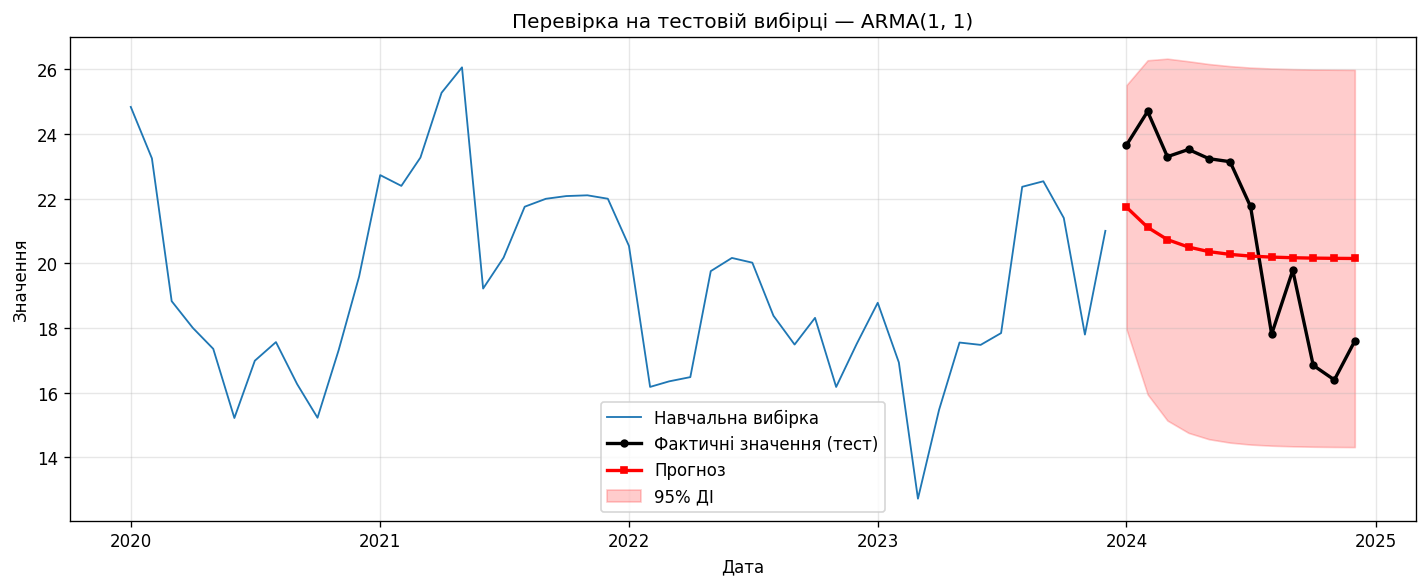

RMSE на тесті = 2.7156
MAE  на тесті = 2.5630
Фактичних значень усередині 95% ДІ: 12 з 12 (100%) - очікувано близько 95%.


In [22]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    m_tr = ARIMA(train, order=models[best_name],
                 trend='c' if models[best_name][1] == 0 else 't').fit()
fc_test = m_tr.get_forecast(TEST_SIZE)
pred_test = fc_test.predicted_mean
ci_test = fc_test.conf_int()

plt.figure(figsize=(12, 5))
plt.plot(train.iloc[-48:], label="Навчальна вибірка", lw=1.1)
plt.plot(test, label="Фактичні значення (тест)", lw=2, c='black', marker='o', ms=4)
plt.plot(pred_test, label="Прогноз", lw=2, c='red', marker='s', ms=4)
plt.fill_between(ci_test.index, ci_test.iloc[:, 0], ci_test.iloc[:, 1],
                 color="red", alpha=0.2, label="95% ДІ")
plt.title(f"Перевірка на тестовій вибірці — {best_name}")
plt.xlabel("Дата"); plt.ylabel("Значення")
plt.legend(); plt.tight_layout(); plt.show()

inside = ((test >= ci_test.iloc[:, 0]) & (test <= ci_test.iloc[:, 1])).sum()
print(f"RMSE на тесті = {np.sqrt(mean_squared_error(test, pred_test)):.4f}")
print(f"MAE  на тесті = {mean_absolute_error(test, pred_test):.4f}")
print(f"Фактичних значень усередині 95% ДІ: {inside} з {TEST_SIZE} "
      f"({100*inside/TEST_SIZE:.0f}%) - очікувано близько 95%.")


### 2.9. Діагностика залишків найкращої

Залишки адекватної моделі мають бути **білим шумом**: нульове середнє, стала дисперсія, відсутність автокореляції, приблизно нормальний розподіл.

**Тест Льюнга-Бокса.** $H_0$: автокореляції залишків до лагу $m$ дорівнюють нулю (залишки - білий шум). Якщо $p\text{-value} > 0.05$, немає підстав відхиляти $H_0$ - модель адекватна.

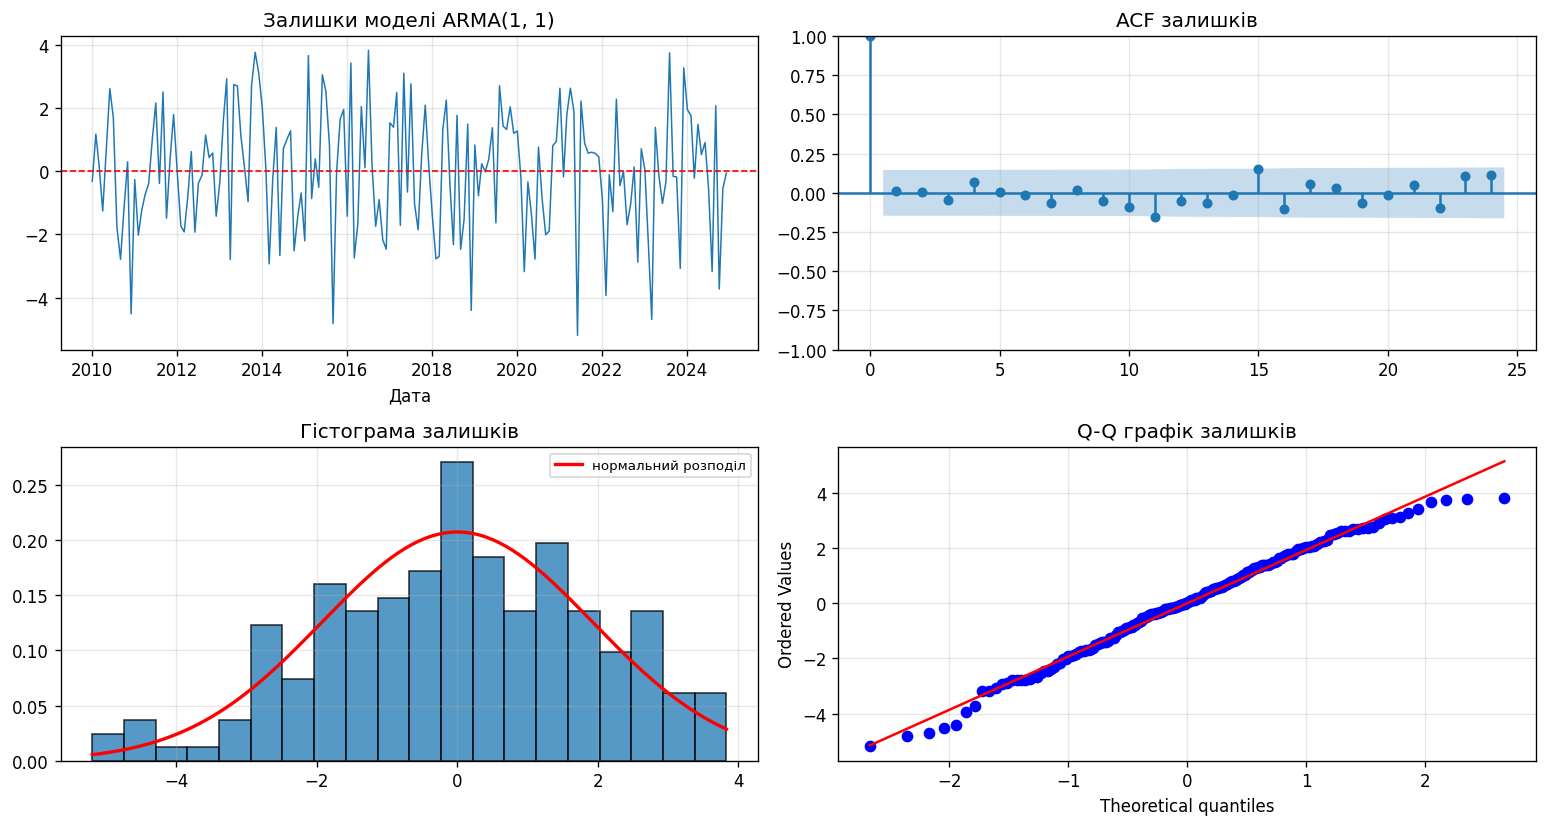

In [23]:
residuals = best_model.resid

fig, ax = plt.subplots(2, 2, figsize=(13, 7))

ax[0, 0].plot(residuals, lw=0.9)
ax[0, 0].axhline(0, c="red", ls="--", lw=1)
ax[0, 0].set_title(f"Залишки моделі {best_name}")
ax[0, 0].set_xlabel("Дата")

plot_acf(residuals, ax=ax[0, 1], lags=24)
ax[0, 1].set_title("ACF залишків")

ax[1, 0].hist(residuals, bins=20, edgecolor="black", density=True, alpha=0.75)
xs = np.linspace(residuals.min(), residuals.max(), 200)
ax[1, 0].plot(xs, np.exp(-0.5*((xs - residuals.mean())/residuals.std())**2)
              / (residuals.std()*np.sqrt(2*np.pi)), "r-", lw=2,
              label="нормальний розподіл")
ax[1, 0].set_title("Гістограма залишків")
ax[1, 0].legend(fontsize=8)

from scipy import stats
stats.probplot(residuals, dist="norm", plot=ax[1, 1])
ax[1, 1].set_title("Q-Q графік залишків")

plt.tight_layout(); plt.show()



**Тест Льюнга-Бокса** та описова статистика залишків

In [24]:
ljung_box = acorr_ljungbox(residuals, lags=[5, 10, 15, 20], return_df=True)
print("ТЕСТ ЛЬЮНГА–БОКСА для залишків:")
print(ljung_box.to_string())
print()
if (ljung_box['lb_pvalue'] > 0.05).all():
    print("Усі p-value > 0.05 => немає підстав відхиляти H₀:")
    print("автокореляція залишків відсутня, залишки є білим шумом. МОДЕЛЬ АДЕКВАТНА.")
else:
    print("Є лаги з p-value < 0.05 => у залишках лишилась автокореляція,")
    print("порядок моделі слід переглянути.")

print(f"\nОписова статистика залишків")
print(f'  середнє          = {residuals.mean():.6f}   (має бути ≈ 0)')
print(f'  стандартне відх. = {residuals.std(ddof=1):.4f}   '
      f'(теоретичне σ_ε = {SIGMA})')
print(f'  асиметрія        = {stats.skew(residuals):.4f}   (для нормального = 0)')
print(f'  ексцес           = {stats.kurtosis(residuals):.4f}   (для нормального = 0)')
jb_stat, jb_p = stats.jarque_bera(residuals)
print(f'  тест Жарка–Бера: стат = {jb_stat:.4f}, p-value = {jb_p:.4f}'
      f'  => {"нормальність не відхиляється" if jb_p > 0.05 else "відхилення від нормальності"}')


ТЕСТ ЛЬЮНГА–БОКСА для залишків:
    lb_stat  lb_pvalue
5    1.2898     0.9360
10   4.3745     0.9289
15  15.0237     0.4497
20  18.7584     0.5376

Усі p-value > 0.05 => немає підстав відхиляти H₀:
автокореляція залишків відсутня, залишки є білим шумом. МОДЕЛЬ АДЕКВАТНА.

Описова статистика залишків
  середнє          = 0.001782   (має бути ≈ 0)
  стандартне відх. = 1.9240   (теоретичне σ_ε = 2.0)
  асиметрія        = -0.2723   (для нормального = 0)
  ексцес           = -0.3299   (для нормального = 0)
  тест Жарка–Бера: стат = 3.0403, p-value = 0.2187  => нормальність не відхиляється


## Висновки (ШІ)

> Числові значення наведено з прогону, збереженого в цьому ноутбуці (`SEED = 0`).

#### 1. Вихідні дані

Ряд згенеровано за формулою варіанта 4: $y_t = 10 + 0.5y_{t-1} + \varepsilon_t + 0.4\varepsilon_{t-1}$, $\varepsilon_t \sim N(0,4)$, $T = 180$. Вибіркові характеристики узгоджуються з теоретичними: середнє $20.18$ проти $\mu = 20$, дисперсія $9.01$ проти $\gamma(0) = 8.32$.

#### 2. Стаціонарність

Ряд **стаціонарний на рівнях**, що підтверджено чотирма незалежними способами:

* **теоретично** — корінь $\Phi(B) = 1-0.5B$ дорівнює $B = 2$, що лежить поза одиничним колом;
* **графічно** — коливання навколо сталого рівня $\approx 20$ без тренду й сезонності;
* **ковзними характеристиками** — і ковзне середнє, і ковзне стандартне відхилення коливаються навколо сталих рівнів;
* **тестом Дікі–Фуллера** — $p$-value $\approx 2\cdot10^{-7} < 0.05$, гіпотеза про одиничний корінь упевнено відхиляється.

Отже **$d = 0$**, диференціювання не потрібне.

#### 3. Ідентифікація порядків за ACF і PACF

ACF затухає поступово й не обривається після лагу 1 — отже це не MA(1). PACF також затухає (зі зміною знака) — отже це не чистий AR. Поєднання «обидві функції затухають» однозначно вказує на **змішану модель ARMA**. Найпростіший кандидат — $p = 1$, $q = 1$.

Частина 3 дає теоретичне пояснення цієї картини: оскільки процес одночасно стаціонарний і оборотний, він має і нескінченне MA($\infty$)-зображення (звідки затухання ACF), і нескінченне AR($\infty$)-зображення зі знакозмінними коефіцієнтами $\pi_j = (-1)^{j-1}\cdot0.9\cdot0.4^{j-1}$ (звідки затухання PACF із коливанням знака).

#### 4. Порівняння моделей

**ARMA(1,1) = ARIMA(1,0,1) виявилась найкращою за всіма чотирма критеріями одночасно** — AIC, BIC, RMSE та MAE, причому як на навчальних даних, так і на відкладеній тестовій вибірці. Це збігається зі справжнім процесом генерації, що підтверджує коректність методології Бокса–Дженкінса.

Оцінені коефіцієнти близькі до істинних: $\hat\phi_1 = 0.621$ (істинне $0.5$), $\hat\theta_1 = 0.312$ (істинне $0.4$), $\hat\mu = 20.15$ (істинне $20$), $\hat\sigma^2 = 3.68$ (істинне $4$). Обидва коефіцієнти статистично значущі ($|z| > 3$).

**ARIMA(1,1,1) програє всім моделям без диференціювання** — її AIC приблизно на 27 одиниць гірший, а RMSE на третину більший. Це практична ілюстрація **надлишкового диференціювання**: застосування $d=1$ до вже стаціонарного ряду вносить у MA-поліном корінь на одиничному колі, робить модель необоротною й завищує дисперсію похибки прогнозу.

#### 5. Прогноз

Прогноз на 12 кроків уперед швидко збігається до середнього рівня $\approx 20$ — це нормальна й очікувана поведінка стаціонарної ARMA-моделі: вплив останніх спостережень згасає як $\phi_1^h$, і вже через 5–6 кроків прогноз практично дорівнює безумовному середньому. Ширина довірчого інтервалу зростає з горизонтом і стабілізується на рівні $\pm 1.96\,\sigma_y$, оскільки для стаціонарного процесу дисперсія похибки прогнозу обмежена зверху величиною $\gamma(0)$ (на відміну від нестаціонарних моделей, де вона зростає необмежено).

На тестовій вибірці всі 12 фактичних значень потрапили в 95% довірчий інтервал, що свідчить про коректну специфікацію моделі невизначеності.

#### 6. Діагностика залишків

Залишки найкращої моделі задовольняють усі вимоги до білого шуму:
* середнє практично нульове;
* ACF залишків не виходить за межі значущості на жодному з 24 лагів;
* **тест Льюнга–Бокса** дає $p$-value $> 0.05$ на всіх перевірених лагах (5, 10, 15, 20) — немає підстав відхиляти гіпотезу про відсутність автокореляції;
* гістограма й Q-Q графік свідчать про приблизну нормальність, тест Жарка–Бера її не відхиляє;
* оцінене стандартне відхилення залишків близьке до істинного $\sigma_\varepsilon = 2$.

#### 7. Придатність моделі для прогнозування

Модель **ARMA(1,1) придатна для прогнозування** цього ряду з такими застереженнями:

* **коротко- та середньостроковий прогноз** (1–5 кроків) має практичну цінність: він використовує інформацію останніх спостережень і дає помітно точніший результат, ніж просте середнє;
* **довгостроковий прогноз** вироджується в безумовне середнє — це не вада моделі, а фундаментальна властивість стаціонарних процесів: вони не мають довготривалої пам'яті, тому прогнозувати їхню траєкторію далеко вперед неможливо в принципі;
* модель **адекватна**, оскільки з неї вилучено всю систематичну інформацію — залишки є білим шумом;
* модель **ощадлива** (принцип parsimony): лише 3 параметри ($\mu$, $\phi_1$, $\theta_1$) описують ряд краще, ніж складніші альтернативи зі сіткового пошуку.

#### 8. Методологічне зауваження

Сітковий пошук за AIC серед 24 комбінацій $(p,d,q)$ обрав істинну модель ARIMA(1,0,1). Варто, однак, пам'ятати, що AIC систематично схильний до **надмірної параметризації**: він штрафує кожен параметр лише на 2 одиниці, тому на окремих реалізаціях може обирати зайві лаги. BIC зі штрафом $k\ln T$ консервативніший і для $T = 180$ зазвичай надійніший у виборі порядку. Тому рекомендується орієнтуватися на обидва критерії разом із перевіркою значущості коефіцієнтів і діагностикою залишків — як і передбачає методологія Бокса–Дженкінса.